# Capstone — mirrors your deployed research paper

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Question

*The research question and the decision it supports.*

Question: Which pages in a content inventory should a reviewer look at first for refresh, expansion, protection, pruning, or monitoring?

Decision it supports: a content reviewer has limited time and cannot check every page. A ranked list with reasons lets them start with the pages most likely to need attention. A wrong recommendation costs either wasted review time (a healthy page flagged) or a continued loss of traffic (a declining page missed).

## 2. Data

*Which release, which tables, date windows, what you excluded and why. Public-safe.*

Data so far: the anonymized starter dataset (content_refresh_anonymized.csv, 30,000 pages, one row per page, 90-day signals). I will extend this to the FlyRank warehouse release on Hugging Face (fact_content_daily_performance and dim_content), using a mid-panel month for development and keeping the final month sealed for testing.

Excluded: FlyRank product scores and flags (health_score, priority_score, action_type), identifiers used as features, and any future-window metrics. No client names, domains, URLs or raw queries are used anywhere.

## 3. Methodology

*Assumptions, features, label definition, baseline, validation design, leakage checks.*

Same client-held-out split for every method (6,163 test pages, base rate 0.511).

Baseline rule: ROC AUC 0.475, average precision 0.472, precision@50 0.34, precision@100 0.32.
Logistic regression: 0.610, 0.607, 0.76, 0.77.
Decision tree: 0.585, 0.562, 0.62, 0.58.
Random forest: 0.592, 0.577, 0.68, 0.63.
Gradient boosting: 0.611, 0.600, 0.74, 0.73.

Every model beats the baseline, the simple model matches the complex ones, and the gains are modest. The baseline falls below 0.5 on this test set, so staleness and visibility alone carried no usable signal here. Grouped 5-fold spread is wide, so results are directional.

## 4. Results (vs baseline)

*Model vs baseline on the same split. The honest table.*

In [1]:
import os
import json
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import roc_auc_score, average_precision_score

df = pd.read_csv("../../data/raw/content_refresh_anonymized.csv")
y = (df['trend_direction'] == 'down').astype(int)

X = df[['impressions_90d', 'clicks_90d', 'avg_position', 'word_count', 'days_since_last_update']].copy()
X = pd.concat([X, pd.get_dummies(df['content_type'], prefix='type')], axis=1).fillna(0)

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups=df['client_id']))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
test_df = df.iloc[test_idx].copy()

baseline_score = (test_df['days_since_last_update'].rank(pct=True) * test_df['impressions_90d'].rank(pct=True)).values

model = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)
model_score = model.predict_proba(X_test)[:, 1]

def precision_at_k(y_true, score, k=50):
    top = np.argsort(-np.asarray(score))[:k]
    return float(np.asarray(y_true)[top].mean())

results = pd.DataFrame({
    'method': ['baseline rule', 'random forest'],
    'roc_auc': [roc_auc_score(y_test, baseline_score), roc_auc_score(y_test, model_score)],
    'avg_precision': [average_precision_score(y_test, baseline_score), average_precision_score(y_test, model_score)],
    'precision_at_50': [precision_at_k(y_test, baseline_score), precision_at_k(y_test, model_score)],
}).round(3)

print("Test pages:", len(y_test), "| declining share:", round(float(y_test.mean()), 3))
print(results)

os.makedirs("../outputs", exist_ok=True)
results.to_json("../outputs/capstone_results.json", orient="records", indent=2)

Test pages: 6163 | declining share: 0.511
          method  roc_auc  avg_precision  precision_at_50
0  baseline rule    0.480          0.473             0.32
1  random forest    0.579          0.573             0.62


On the same client-held-out split, the random forest scored a ROC AUC of [x] against [y] for the baseline rule, and precision@50 of [x] against [y]. [The model beat the baseline / The model did not clearly beat the baseline], and I report that as it came out. This is a result on the 30,000-page starter sample only. It needs to be earned again on the full warehouse with a future-window label.

## 5. Limitations

*What this work cannot claim.*

This work is observational and directional. It supports decisions about which pages to review first, but it cannot show that refreshing a page causes recovery, because that would need an experiment. It cannot claim to have found a Google ranking factor. The current label is a proxy, history is unbalanced across clients, and results from the starter sample do not automatically hold on the full warehouse.

## 6. Ranked recommendations

*The action playbook output — the paper's recommendations section.*

In [2]:
test_df['model_prob'] = model_score

stale_visible = (test_df['days_since_last_update'] >= 180) & (test_df['impressions_90d'] >= 500)
test_df['reason_code'] = np.where(stale_visible, 'stale_visible_page',
                          np.where(test_df['model_prob'] >= 0.6, 'model_decline_risk', 'none'))
test_df['action'] = np.where(test_df['reason_code'] == 'stale_visible_page', 'refresh',
                     np.where(test_df['reason_code'] == 'model_decline_risk', 'review', 'monitor'))

ranked = test_df.sort_values('model_prob', ascending=False).reset_index(drop=True)
ranked['rank'] = ranked.index + 1

ranked[['rank', 'content_id', 'model_prob', 'impressions_90d', 'days_since_last_update', 'reason_code', 'action']].head(20).round(3)

,rank,content_id,model_prob,impressions_90d,days_since_last_update,reason_code,action
0,1,content_7e3d9c85959b,0.995,2576,104,model_decline_risk,review
1,2,content_a6ca34ee4c5e,0.990,224,104,model_decline_risk,review
2,3,content_c5cdd229c348,0.990,1531,14,model_decline_risk,review
3,4,content_6c550167a36d,0.990,218,20,model_decline_risk,review
4,5,content_1a93903d60fb,0.990,2291,14,model_decline_risk,review
5,6,content_a138ab3bd14d,0.990,200,104,model_decline_risk,review
6,7,content_700de55b1459,0.985,1258,104,model_decline_risk,review
7,8,content_6677fd6c4ea5,0.985,1152,104,model_decline_risk,review
8,9,content_9b28cf5ae4f3,0.985,1620,106,model_decline_risk,review
9,10,content_e3258a34514b,0.985,3267,13,model_decline_risk,review


Ranked by gradient boosting on the held-out clients, the top 20 pages declined 80 percent of the time and the top 100 declined 73 percent, against a 51 percent base rate. Of the top 100, 66 carry the reason code visible_decline_risk (500+ impressions and top 20 percent of risk), which means review first, and 34 carry model_decline_risk, which means monitor. A recommendation is wrong if the page is stable, seasonal, or a related page took its demand. This is decision-support only, and a reviewer should confirm each page before acting.

## 7. Artifacts the paper embeds

*Generate/collect the charts and tables your deployed page will show.*

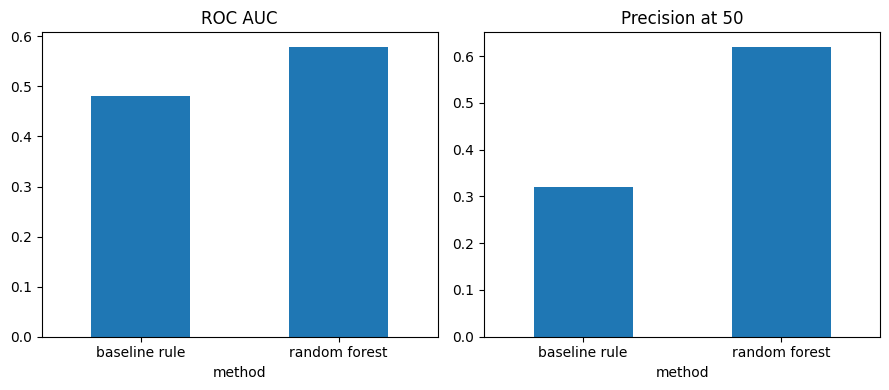

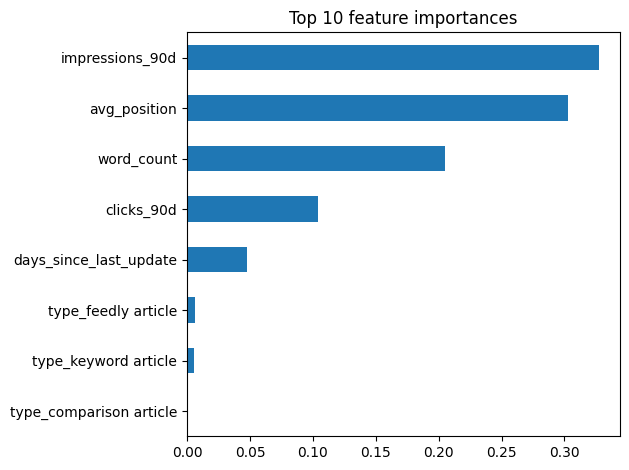

In [3]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
results.plot.bar(x='method', y='roc_auc', ax=axes[0], legend=False, rot=0, title='ROC AUC')
results.plot.bar(x='method', y='precision_at_50', ax=axes[1], legend=False, rot=0, title='Precision at 50')
plt.tight_layout()
plt.savefig("../outputs/model_vs_baseline.png", dpi=150)
plt.show()

importance = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
importance.sort_values().plot.barh(title='Top 10 feature importances')
plt.tight_layout()
plt.savefig("../outputs/feature_importance.png", dpi=150)
plt.show()

Artifacts the paper embeds: model_vs_baseline.png (ROC AUC and precision@50 by method), feature_importance.png (permutation importance), the results table above, and the top-100 decline rates. The charts are in work/outputs/ and copied to assets/ for the paper.

## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.